# 04 · D3R: compressing a plant model into a few numbers

**Where this sits in the chain:** process model → parameter identification → *dimension reduction* → grid/aggregator optimization.

A grid or planning model would like to include thousands of factories, but each detailed process model (STN/RTN) brings its own binaries, and exact aggregation of many such models is computationally hard. Data-driven dimension reduction (D3R) replaces each detailed model with **reduced constraints** that are simple and linear, chosen so that their **optimal response to prices** mimics the detailed model's.

*References:* thesis Ch. 4; R. Lyu et al., "Data-Driven Dimension Reduction for Industrial Load Modeling Using Inverse Optimization," *IEEE Trans. Smart Grid* 16(3), 2025; paper code: [Data-Driven-Dimension-Reduction](https://github.com/ruikelyu/Data-Driven-Dimension-Reduction).

Everything here runs with the free HiGHS solver, in seconds.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import indflex as fx
from indflex.identify import make_meter_dataset
from indflex.reduce import ALFParams, build_alf, fit_alf, simulate_alf, nrmse_paper

plt.rcParams["figure.dpi"] = 110

## 1. The detailed model and its responses

We take the **cement plant STN** from notebook 01 (4 machines with on/off modes, buffers between them) and record its optimal hourly load under PJM prices. We use these days for training and later check on July 22–31. The data is in MWh and $/kWh, as in the paper.

detailed model (STN): 192 binary + 100 continuous variables per day


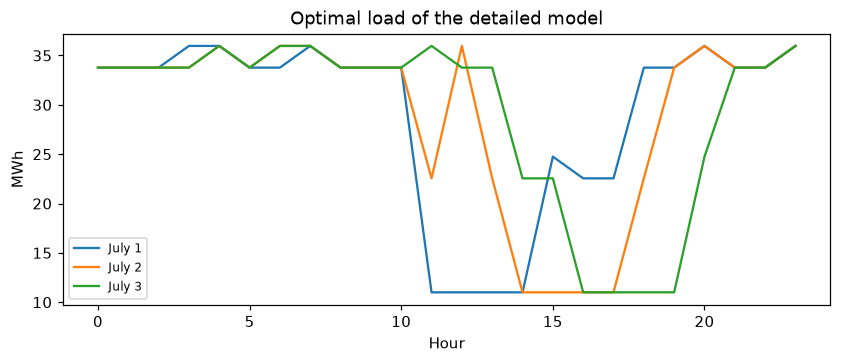

In [2]:
plant = fx.load_plant("cement_golmohamadi2020")
ds = make_meter_dataset(plant)
n_bin, n_cont = fx.count_vars(fx.build_stn(plant, ds.price_train[0] * 1000))
print(f"detailed model (STN): {n_bin} binary + {n_cont} continuous variables per day")

fig, ax = plt.subplots(figsize=(9, 3.2))
for d in range(3):
    ax.plot(ds.load_train[d], label=f"July {d + 1}")
ax.set(title="Optimal load of the detailed model", xlabel="Hour", ylabel="MWh"); ax.legend(fontsize=8); plt.show()

## 2. The reduced form: an adjustable load fleet (ALF)

The plant is approximated by $I$ adjustable loads in parallel. Load $i$ draws $p_{t,i}$ with

$$\underline P_i \le p_{t,i} \le \overline P_i \quad\text{(every hour)},\qquad \underline E_i \le \textstyle\sum_t p_{t,i}\,\Delta t \le \overline E_i \quad\text{(over the day)},$$

and the plant's load is $\sum_i p_{t,i}$. That is **4 numbers per load**, and the plant's response to a price becomes a tiny LP. The ALF keeps three features of industrial loads: several pieces of equipment, rated powers, and a daily production goal (energy).

## 3. Learning the ALF by inverse optimization

We want ALF parameters whose **optimal** response reproduces the detailed model's. As in notebook 03, we write the ALF's optimality (KKT) conditions as constraints and let the parameters be variables. Here the complementary-slackness conditions are linearized with big-M binaries, so the problem has no bilinear terms:

* squared-error loss → mixed-integer QP (Gurobi, as in the paper);
* absolute-error loss → **MILP, which the free HiGHS solver handles**.

For one adjustable load and three days of data, **one solve** is enough:

In [3]:
alf, info = fit_alf(ds.price_train[:3], ds.load_train[:3], n_loads=1, solver="highs")
print(f"{info['status']} in {info['seconds']:.1f} s ({info['binaries']} binaries in the inverse problem)")
alf.as_frame()

optimal in 3.0 s (150 binaries in the inverse problem)


,P_min,P_max,E_min,E_max
load 1,11.0,33.77,708.18,708.18


The learned ALF says: the plant always draws between $\underline P$ and $\overline P$ and must use a fixed amount of energy per day (a production target, so $\underline E \approx \overline E$). Its flexibility is *when* it uses that energy.

## 4. Check on unseen prices (July 22–31)

First, what the learned ALF allows: hourly power anywhere in the band $[\underline P, \overline P]$, with a fixed daily energy. Under each price it draws as little as possible in the expensive hours, as long as it still uses its daily energy. Below, the band and the ALF's response to three unseen days (top), and the detailed model's response to the same days (bottom):

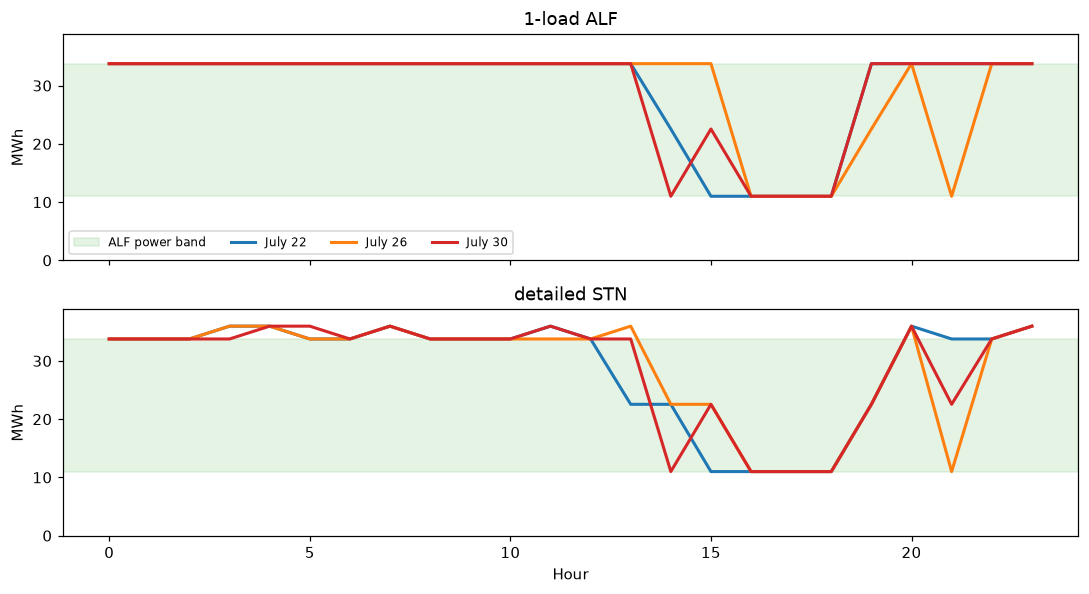

In [4]:
pred = simulate_alf(alf, ds.price_cv)
fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
for ax, (label, loads) in zip(axes, [("1-load ALF", pred), ("detailed STN", ds.load_cv)]):
    ax.axhspan(alf.p_min.sum(), alf.p_max.sum(), color="tab:green", alpha=0.12, label="ALF power band")
    for d, c in zip([0, 4, 8], ["C0", "C1", "C3"]):
        ax.plot(loads[d], color=c, lw=2, label=f"July {22 + d}")
    ax.set(ylabel="MWh", title=label, ylim=(0, alf.p_max.sum() * 1.15))
axes[0].legend(fontsize=8, ncol=4, loc="lower left"); axes[1].set_xlabel("Hour")
plt.tight_layout(); plt.show()

How close is the ALF's response to the detailed model on each held-out day?

nRMSE vs. the detailed model: 9.3%   (paper, 1 load: 8.9%)


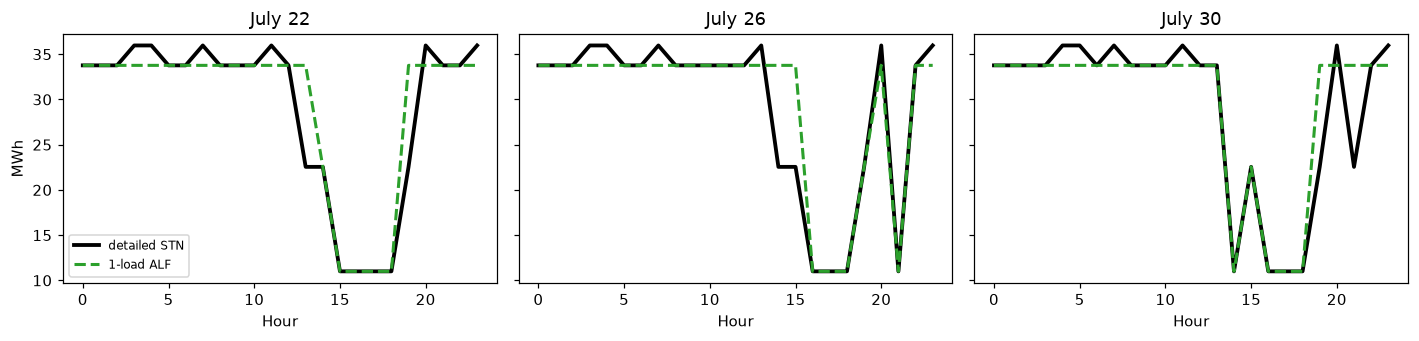

In [5]:
pred = simulate_alf(alf, ds.price_cv)
print(f"nRMSE vs. the detailed model: {100 * nrmse_paper(pred, ds.load_cv):.1f}%   (paper, 1 load: 8.9%)")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for ax, d in zip(axes, [0, 4, 8]):
    ax.plot(ds.load_cv[d], "k", lw=2.5, label="detailed STN")
    ax.plot(pred[d], "--", color="tab:green", lw=2, label="1-load ALF")
    ax.set(title=f"July {22 + d}", xlabel="Hour")
axes[0].set_ylabel("MWh"); axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

The errors are errors in the **optimal response** under new prices. The ALF does not guarantee that its schedules are feasible for the detailed plant; in practice, the detailed model (or the plant itself) turns the reduced model's decision into an executable schedule.

**More loads, better fit.** A second adjustable load lets the ALF represent equipment with different flexibility. Set `RUN_TWO_LOADS = True` to fit it: about a minute with HiGHS, or about 20 s with `solver="gurobi"`. In our runs the error fell to about 3%.

In [6]:
RUN_TWO_LOADS = False

if RUN_TWO_LOADS:
    alf2, info2 = fit_alf(ds.price_train[:3], ds.load_train[:3], n_loads=2, solver="highs", time_limit=120)
    print(f"{info2['status']} in {info2['seconds']:.0f} s, nRMSE {100 * nrmse_paper(simulate_alf(alf2, ds.price_cv), ds.load_cv):.1f}%")
    display(alf2.as_frame())

## 5. Why this matters for the grid

The reduced model is an LP with $4I$ parameters, so many plants are cheap to handle together. Compare the size of the two models for one plant-day:

In [7]:
alf_bin, alf_cont = fx.count_vars(build_alf(alf, ds.price_cv[0]))
pd.DataFrame({"binary variables": [n_bin, alf_bin], "continuous variables": [n_cont, alf_cont]},
             index=["detailed STN", f"ALF, {alf.n_loads} load"])

,binary variables,continuous variables
detailed STN,192,100
"ALF, 1 load",0,24


For the steelmaking line of notebook 02, the paper replaces **10,208 integer variables with 24 continuous ones** at 3.6% error.

**When is iteration needed?** One solve becomes too large with many days or many loads, since each day adds its own binaries. The paper's code then solves small random batches of days and moves the parameters a small step toward each batch's solution (`indflex.reduce.train_d3r`).

**Takeaways**
* D3R learns reduced constraints from the detailed model's *optimal responses*, using the same inverse-optimization idea as PSI.
* An adjustable load fleet captures the main features of industrial flexibility with a handful of numbers, and it fits in any LP.
* Next in the chain: operate many flexible resources together → **notebook 05: virtual power plant**.